# Récapitulatif E0–E3 : SAGE contre Sem-Detect sur Sem-Detect DB et APRDB

Ce notebook a deux rôles.

1. **Consigner** tout ce qui a été fait depuis l'intégration de Sem-Detect DB : les opérations, les décisions, les bugs corrigés et les résultats obtenus (sections 1.1 à 1.7). Ces chiffres sont **historiques** : ils viennent des notebooks `semdetect_*` et des logs de `run_eval`.
2. **Recalculer et comparer**, à partir des caches et sans aucun appel LLM :
   - Sem-Detect en configurations E0, E1 et E2 sur le test Sem-Detect, puis E3 (pilote) sur APRDB ;
   - SAGE, avec ses deux modèles (entraîné sur APRDB et entraîné sur Sem-Detect), sur **exactement les mêmes cibles** ;
   - des comparaisons appariées, avec des IC95 par bootstrap en grappes (papier pour Sem-Detect DB, `review-id` pour APRDB).

## Exécution

| Partie | Cellules | GPU | Durée indicative |
|---|---|---|---|
| Configuration, métriques, chargement de SAGE | 1 à 3 | aucun | < 1 min |
| A. Sem-Detect DB : Sem-Detect E0, E1, E2 | 4 à 6 | aucun si les caches sont complets | 1 à 2 min |
| A. Sem-Detect DB : scores SAGE (4 410 textes × 2 modèles) | 7 | **GPU 1 libre** (segmentation) | ≈ 25 min la première fois, puis cache |
| A. Comparaisons et figures | 8 à 10 | aucun | 2 à 3 min (bootstrap) |
| B. APRDB pilote : Sem-Detect E3 (a) et (b) | 11 | aucun | < 1 min |
| B. APRDB pilote : scores SAGE (≈ 1 918 textes × 2 modèles) | 12 | **GPU 1 libre** | ≈ 12 min la première fois, puis cache |
| B. Comparaisons et figures ; C. synthèse ; export | 13 à 16 | aucun | 2 à 3 min |

Les numéros sont ceux des commentaires `# … — cellule N` en tête de chaque cellule de code.

**Prérequis.**

- **Le GPU 1 doit être libre** pour les cellules 7 et 12 : `segment_texts` de SAGE place ses modèles (actes de langage, subjectivité) sur `cuda:1`, en dur. Si vLLM tourne encore, l'arrêter avant (`VLLMManager(gpu=1).stop()` ou la session tmux `vllm`).
- Les caches doivent exister : `sem_detect_store` (E0, E1, E2, E3), `sem_detect_e2/local_refs.parquet`, `sem_detect_e3/pilot_universe.parquet`, et les artefacts SAGE dans `RESULT_DIR`.
- Les scores SAGE sont mis en cache dans `CACHE_DIR/recap/`, indexés par identifiant **et** par empreinte MD5 du texte : relancer le notebook ne refait aucun calcul.

Chaque cellule de recalcul affiche les **valeurs attendues** (historiques) à côté des valeurs recalculées. Un écart signale un cache modifié ou une dérive du code ; il faut le comprendre avant de lire les comparaisons.

# 1. Récapitulatif des expérimentations

## 1.1 La question

On compare deux familles de détecteurs de reviews générées par IA, sur deux datasets.

- **SAGE** (notre détecteur). C'est un GRU sur la séquence des segments d'une review : un one-hot d'acte de langage (Assertion, Expressive, Question, Suggestion) et un z-score de subjectivité par segment. La spec est `v3_multi_novalid` (6 features par segment) et le modèle compte **3 873 paramètres**. Il n'utilise **aucune référence** : le score est une fonction du seul texte cible.
- **Sem-Detect** (Duarte et al., 2026, [arXiv:2605.21713](https://arxiv.org/abs/2605.21713)). Un LLM extrait les *claims* de la review en 5 catégories, dont 3 sémantiques (evaluation, constructiveInput, clarificationDialogue). Ces claims sont plongées avec Qwen3-Embedding-0.6B, puis comparées à celles de **k = 3 reviews IA de référence du même papier et de la même note**. On obtient 5 features sémantiques, auxquelles s'ajoutent 4 features textuelles calculées avec Mistral-7B-Instruct-v0.3 (perplexité, score Fast-DetectGPT simplifié, pourcentage top-k avec k = 200, entropie). Un LightGBM à 3 classes (`ai`, `rewrite`, `human`) fait la décision, avec un seuil de similarité τ = 0,8.

**La différence structurelle à garder en tête.** Sem-Detect a besoin, à l'inférence, de reviews IA du **même papier**. SAGE n'en a pas besoin. Toute comparaison doit donc préciser d'où viennent les références de Sem-Detect : c'est l'objet du plan factoriel E0 à E3.

## 1.2 Les données

| | APRDB (Yu et al., 2025, [arXiv:2502.19614](https://arxiv.org/abs/2502.19614)) | Sem-Detect DB (Duarte et al., 2026) |
|---|---|---|
| Conférences | ICLR et NeurIPS, 2016 à 2021 | ICLR et NeurIPS, 2021 et 2022 |
| Classes | humain, IA | humain, réécrit par LLM (`rewrite`), IA |
| Générateurs | GPT-4o, Claude 3.5, Gemini 1.5 Pro, Qwen 2.5 72B, Llama 3.1 70B | Gemini 2.5 Flash, Gemini 2.5 Pro, DeepSeek-V3.1, Qwen3-235B |
| Structure | un `review-id` regroupe une review humaine et jusqu'à 5 « jumelles » IA, générées à partir du papier et de la décision, **sans le texte humain** (annexe E.1) | chaque review IA est conditionnée sur la **note** d'un relecteur humain du même papier |
| Prétraitement d'origine | aucun nettoyage différencié | reviews IA et réécrites nettoyées par LLM (markdown et puces retirés), humaines non nettoyées : **asymétrie dépendante du label** |
| Ensemble évalué ici | test, 9 468 cibles (configuration `sage_gru_2_cat`), et un pilote de 1 000 `review-id` | test, 4 410 reviews (606 humaines, 2 440 réécrites, 1 364 IA), 159 papiers |

**Ce que nous avons corrigé ou fixé dans le chargeur Sem-Detect** (`SemDetectDataset`, `_LOADER_VERSION = 3`) :

- **révision HF figée** : `18b74b551670bff6b04e57570232a1694997863b` ;
- **identifiant composite** `conf-year-submission_id-review_id`, car le `review_id` brut n'est pas unique ;
- **collisions d'identifiants** : 44 doublons stricts supprimés dans le test. Dans le train, 22 humaines en collision (3 soumissions NeurIPS 2021 qui fusionnent deux papiers) et 88 réécritures devenues orphelines sont exclues ;
- **split de validation** virtuel au niveau papier (`val_fraction = 0,1`, tirage MD5 stable) : 568 papiers en train, 66 en validation et 159 en test, après exclusions ;
- **équilibrage apparié** (`balance = paired`) : pour chaque humaine, la réécriture de cette humaine et une IA du même papier et de la même note, sans remise. On obtient 2 176 groupes en train et 249 en validation.

## 1.3 Les détecteurs tels qu'utilisés

| Modèle | Données d'entraînement | Artefact | Remarque |
|---|---|---|---|
| **SAGE-APRDB** | calibration APRDB (preset `train_sage_gru_v3`) | hash `40267e07…` | AUC de validation 0,9549 |
| **SAGE-SD** | train Sem-Detect apparié, binaire humain contre IA (preset `train_sage_gru_v3_semdetect`) | hash calculé en cellule 3 | même spec, même architecture et mêmes hyperparamètres que SAGE-APRDB : seule la source des données change |
| **Sem-Detect** | train Sem-Detect (modèle publié par les auteurs) | `lightgbm_best_model.pkl` | code d'origine copié sans modification dans `src/detector/sem_detect/semdetect/` |

## 1.4 Chronologie des opérations

**Phase 1 : intégration de Sem-Detect DB dans le hub.** `SemDetectDataset`, `dataset_factory` (dispatch APRDB ou Sem-Detect), config `conf/dataset/sem_detect.yaml`. Les réécritures sont exclues pour le binaire. Le diagnostic des doublons a été fait en notebook (voir 1.2).

**Phase 2 : SAGE-APRDB évalué sur Sem-Detect (transfert).**

- `sage.py` a été réécrit pour lire trois générations d'artefacts : legacy (clé `model`), intermédiaire (`ctx` reconstruit depuis `artifact['cfg']`) et actuelle. La spec est résolue par nom, ou par structure si elle a été renommée (`v3` est devenue `v3_multi_novalid`). `_align` remet les scores dans l'ordre des textes et échoue plutôt que de les décaler.
- `run_eval.py` persiste désormais les prédictions (`eval_predictions/<hash>/predictions.parquet`) et résout la config d'entraînement avant de la greffer, ce qui a corrigé une `InterpolationKeyError`.
- **Contamination** (shingles de 12 mots) : 53 reviews humaines 2021 du test Sem-Detect (ICLR 22 sur 148, NeurIPS 31 sur 112) apparaissent dans la calibration APRDB. Elles sont listées dans `contamination/semdetect_test_vs_aprdb_calibration_2016-2021.txt`.

**Phase 3 : SAGE entraîné sur Sem-Detect.** Ajouts : `n_outputs` dans `SimpleGRU`, `_check_val_split`, et chemin apparié dans `gru_train.py`. Le résultat en distribution (AUC 0,9999) est **suspect** : gabarit de prompt unique, longueur, et surtout asymétrie de prétraitement liée au label (les puces retirées côté IA changent la segmentation en phrases, donc la séquence d'actes de langage). Les diagnostics A, B et C sont préparés, mais **pas lancés**.

**Phase 4 : Sem-Detect en local, sans API.** Contraintes : 2 × RTX A6000 de 48 Go, 150 Go de RAM, 0 € dépensé sur un budget maximal de 50 €.

- Les claims sont extraites par vLLM 0.11 (serveur compatible OpenAI sur le GPU 1, profils `.env`, `VLLMManager`, watchdog de 2 h) ; les features tournent sur le GPU 0.
- `SemDetectFeatureStore` v2 sépare deux caches : les embeddings, indexés par source de claims, et les statistiques textuelles, indexées par source de texte. Les caches textuels sont donc partagés entre E0, E1 et E2.
- `references.py` regroupe `paper_protocol_references` (protocole du papier §3.2, `is_valid`, `key_cols`), `fixed_models_references` (protocole sans recours aux labels) et `build_feature_matrix`, qui reprend les règles d'exclusion du script officiel et renvoie les exclusions.
- **Fuite dans le script officiel** `scripts/evaluate.py` : la cible est sa propre référence dans 46,6 % des cibles IA, et des références du même modèle sont utilisées. On applique donc le protocole du papier.

**Phase 5 : plan factoriel.**

| | Claims | Références | Cibles | Ce que le contraste isole |
|---|---|---|---|---|
| **E0** | Gemini (fournies par le dataset) | IA du dataset, même papier et même note | test Sem-Detect | reproduction du papier |
| **E1** | Qwen3-32B local | IA du dataset | test Sem-Detect | E1 − E0 : effet de l'extracteur |
| **E2** | Qwen3-32B local | générées localement : Mistral-Small-3.2 (FP8), Gemma-3-27B, GLM-4-32B ; protocole `fixed_models` | test Sem-Detect | E2 − E1 : effet de références non issues de la campagne de génération |
| **E3** | Qwen3-32B local | jumelles natives d'APRDB (R2), même `review-id` | APRDB test (pilote) | transfert de domaine |

**Choix de l'extracteur** (100 reviews ; Gemini en extrait 15,4 claims sémantiques par review en moyenne, et r est la corrélation avec ces comptes Gemini) :

| Modèle | Claims sémantiques / review | r |
|---|---|---|
| Qwen3-8B | 12,2 | 0,680 |
| Qwen3-14B | 13,5 | 0,764 |
| Qwen3-14B avec *thinking* | 12,0 | 0,631 |
| Qwen3-30B-A3B | 12,7 | 0,692 (une génération en boucle) |
| **Qwen3-32B (AWQ), retenu** | **13,8** | **0,796** |

Le débit est de 1,9 s par review avec 32 requêtes en parallèle.

**Phase 6 : E3, audit d'APRDB puis pilote.** Voir 1.5.

## 1.5 Résultats historiques

### SAGE

| Modèle → test | N (humain / IA) | AUC | TPR@1 % | Remarque |
|---|---|---|---|---|
| SAGE-APRDB → APRDB test | 9 468 | **0,9548** | 0,456 | TPR@5 % 0,760 ; validation 0,98 sur NeurIPS/ICLR 2021 |
| SAGE-APRDB → Sem-Detect test | 606 / 1 364 | **0,7168** | 0,188 | au seuil 0,5 : précision 0,925, rappel 0,334 (IA vues comme humaines) |
| SAGE-APRDB → Sem-Detect test, décontaminé | 553 / 1 364 | 0,7204 | 0,188 | aucun effet de mémorisation |
| SAGE-SD → Sem-Detect test | 606 / 1 364 | **0,9999** | 0,998 | **suspect** (raccourci de forme) |
| SAGE-APRDB → Sem-Detect 2022 seul | | non rapporté | | |

### Sem-Detect sur le test Sem-Detect (E0, E1, E2)

| | E0 : Gemini + réf. dataset | E1 : Qwen3-32B + réf. dataset | E2 : Qwen3-32B + réf. locales |
|---|---|---|---|
| Cibles classées / 4 410 | 4 373 | 4 366 | 3 165 |
| Macro-F1 (3 classes) | **0,8418** (papier : 0,84) | 0,8258 | 0,7345 |
| Δ macro-F1 apparié | | −0,0158 [−0,0258 ; −0,0064] vs E0 | −0,0905 [−0,1036 ; −0,0771] vs E1 |
| Rappel IA (argmax) | 0,911 | 0,843 | 0,552 |
| AUC humain / IA (P(ai)) | 0,998 (papier : 0,999) | 0,9963 | 0,989 |
| TPR@1 % humain / IA | 0,928 (papier : 0,973) | 0,927 | 0,806 |
| AUC (humain + réécrit) / IA | 0,9912 | | 0,954 |

- **E0, matrice de confusion** (% par ligne vraie ; lignes IA, réécrit, humain) : [91,13 ; 8,58 ; 0,29], [3,20 ; 92,32 ; 4,48] et [0,83 ; 34,72 ; 64,44]. Avec le protocole du script officiel (qui fuit), la macro-F1 monte à 0,850–0,853 et le rappel IA à environ 0,99. Le score binaire retenu est P(ai), meilleur que 1 − P(human).
- **E1** : 44 cibles non classables, après relance ciblée des échecs d'extraction et choix des références parmi les candidates valides (étape A). Deux features se décalent : la diversité intra-review de −0,5 σ et la log-longueur de −0,26 σ.
- **E2** : 1 245 cibles non classables, parce qu'environ 10 % des références sont devenues invalides. Le nettoyage d'origine ne garde que le premier bloc `{{{…}}}`, et Qwen3-32B entoure probablement chaque section de sa sortie d'accolades. Le taux varie selon le modèle : Gemma 2,1 %, GLM 9,4 %, Mistral 17,9 %. **Non corrigé** : le Δ de E2 est une **borne haute** de la dégradation. L'écart de similarité de meilleur appariement IA − humain passe de 0,104 à 0,077 (humaines inchangées à 0,634). Rappel IA par générateur de la cible : Gemini Pro 0,45, Qwen3 0,41, DeepSeek 0,65, Flash 0,70.

### E3 : audit d'APRDB

- Réservoir de 101 890 reviews, dont 17 013 humaines (une par `review-id`). 5 couples (`review-id`, générateur) ambigus sont exclus. Les références R2 couvrent 99,98 % des cibles.
- Après `strip_markdown`, il reste des puces dans **50,7 % des IA contre 18,9 % des humaines**. Dans le train de Sem-Detect, les IA n'en avaient pas.
- **NeurIPS 2021** : les IA y sont plus courtes que les humaines (gabarit JSON, champ `main_review`), l'inverse de toutes les autres éditions.
- 8,5 % des humaines font moins de 800 caractères, contre 0,5 % des IA.

### E3 : pilote (1 000 `review-id`, Sem-Detect seul)

| | (a) `strip_markdown` | (b) + retrait des marqueurs de liste |
|---|---|---|
| Cibles classées | 1 850 (≈ 905 IA, 945 humaines) | 1 850 |
| Non classables | 68, dont 55 humaines | 68 |
| AUC | **0,980** | 0,982 |
| TPR@1 % | **0,699** | 0,648 |
| TPR@5 % | 0,923 | 0,928 |
| Décisions : IA → ai / rewrite / human | 42 % / 57 % / 0,8 % | 42 % / 57 % / 1,1 % |
| Humaines → ai | 0,2 % | 0,1 % |

- **Par générateur, en (a)** (AUC / TPR@1 %) : gemini 0,983 / 0,692, gpt4o 0,968 / 0,710, llama 0,971 / 0,474, qwen 0,995 / 0,881.
- **NeurIPS 2021** : AUC de 0,926, contre au moins 0,984 pour toutes les autres éditions.
- La similarité de meilleur appariement est de 0,735 pour les IA et de 0,643 pour les humaines, soit un écart de 0,092 ≈ celui d'E0.
- La variante (b) n'a **pas d'effet établi**.

## 1.6 Ce que ce notebook ajoute

Trois résultats **nouveaux**, pas encore vus :

1. **SAGE-APRDB sur les mêmes cibles que Sem-Detect**, sur Sem-Detect DB comme sur le pilote APRDB : la comparaison devient appariée.
2. **SAGE-SD sur APRDB** : le transfert inverse, prévu parmi les diagnostics du raccourci.
3. **Les écarts appariés avec IC95 en grappes** entre détecteurs, au lieu de chiffres obtenus sur des ensembles différents.

Les commentaires sur ces résultats sont laissés à la lecture des cellules : aucune valeur n'est écrite d'avance.

## 1.7 Précautions de lecture

- **Les ensembles diffèrent selon la configuration.** Sem-Detect exclut les cibles qui ont moins de 4 claims sémantiques ou moins de 3 références valides. Ces exclusions touchent surtout des **humaines courtes**, sans doute faciles. Toutes les comparaisons de ce notebook se font donc sur l'**intersection** des cibles classées, et l'effet de sélection est mesuré à part pour SAGE.
- **Résolution du TPR à faible FPR.** Avec environ 600 humaines (Sem-Detect DB) ou 945 (pilote), le TPR@1 % repose sur 6 à 9 faux positifs au plus. Ses IC sont larges, et le TPR@0,1 % n'est pas estimable.
- **Le bootstrap se fait en grappes** : par papier (`submission_id`) sur Sem-Detect DB, par `review-id` sur APRDB. Les cibles d'une même grappe partagent le papier, et sur APRDB elles partagent aussi leurs références. Un bootstrap au niveau de la cible sous-estimerait la variance.
- **Les régimes ne sont pas symétriques.** Sem-Detect sur APRDB bénéficie de références issues de la **même campagne de génération** que les cibles IA (R2). C'est une condition favorable, que E2 a montré ne pas tenir en déploiement.

In [17]:
# notebook : semdetect_sage_recap.ipynb — cellule 1 : imports et configuration
import hashlib
import logging
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import auc, confusion_matrix, f1_score, precision_recall_fscore_support, roc_auc_score, roc_curve

from src.config import PROJ_ROOT, RESULT_DIR
from src.data.dataset_semdetect import SemDetectDataset
from src.detector.sem_detect.claims_llm import LocalClaimExtractor
from src.detector.sem_detect.feature_store import SemDetectFeatureStore
from src.detector.sem_detect.references import (
    build_feature_matrix, fixed_models_references, paper_protocol_references, predict_proba,
)
from src.detector.sem_detect.semdetect.classifier import FEATURE_DISPLAY_NAMES, SemDetectClassifier
from src.detector.sem_detect.text_cleaning import CLEANERS

logging.basicConfig(level=logging.INFO)
logging.getLogger("httpx").setLevel(logging.WARNING)

CACHE_ROOT = Path(os.environ["CACHE_DIR"])
STORE_ROOT = CACHE_ROOT / "sem_detect_store"
E2_DIR = CACHE_ROOT / "sem_detect_e2"
E3_DIR = CACHE_ROOT / "sem_detect_e3"
RECAP_DIR = CACHE_ROOT / "recap"
RECAP_DIR.mkdir(parents=True, exist_ok=True)

REVISION = "18b74b551670bff6b04e57570232a1694997863b"
HF_SOURCE = f"hf:Sem-Detect/ML_Conferences-Peer-Reviews@{REVISION}"   # claims Gemini du dataset
TEXT_SOURCE = f"{HF_SOURCE}:clean_review"                              # textes du dataset
CLAIMS_TAG_EXPECTED = "vllm:qwen3-32b:0902bb5d60"                      # Qwen3-32B, E1/E2/E3
CONTAM_PATH = CACHE_ROOT / "contamination" / "semdetect_test_vs_aprdb_calibration_2016-2021.txt"

FEATURES_DEVICE = "cuda:0"   # aucun modèle n'est chargé si les caches sont complets
SAGE_DEVICE = "cuda:0"       # GRU de SAGE ; sa segmentation utilise cuda:1 (codé en dur dans segment_texts)
SAGE_PRESETS = {"SAGE-APRDB": "train_sage_gru_v3", "SAGE-SD": "train_sage_gru_v3_semdetect"}
N_BOOT = 1000
METRIC_NAMES = ["AUC", "TPR@1%", "TPR@5%"]

# couleur et style fixés par détecteur (palette catégorielle validée, ordre fixe ; style = encodage secondaire)
STYLE = {
    "Sem-Detect E0": ("#2a78d6", "-"),
    "Sem-Detect E3 (a)": ("#2a78d6", "-"),
    "SAGE-APRDB": ("#eb6834", "--"),
    "SAGE-SD": ("#1baf7a", (0, (5, 1, 1, 1))),
    "Sem-Detect E1": ("#eda100", "-."),
    "Sem-Detect E3 (b)": ("#eda100", "-."),
    "Sem-Detect E2": ("#e87ba4", ":"),
}
TABLES = {}   # tout ce qui est exporté en section 8

In [18]:
# notebook : semdetect_sage_recap.ipynb — cellule 2 : métriques, bootstrap en grappes, affichage
def all_metrics(y: np.ndarray, s: np.ndarray) -> dict:
    """AUC et TPR à FPR fixé à partir d'une seule courbe ROC.
    Même interpolation que get_tpr_at_fpr du hub, sans l'inversion automatique quand AUC < 0,5."""
    fpr, tpr, _ = roc_curve(y, s)
    return {"AUC": float(auc(fpr, tpr)),
            "TPR@1%": float(np.interp(0.01, fpr, tpr)),
            "TPR@5%": float(np.interp(0.05, fpr, tpr))}


def make_evalset(ids, y, clusters, n_boot: int = N_BOOT, seed: int = 0) -> dict:
    """Ensemble d'évaluation figé : ids, labels (1 = IA) et rééchantillonnages bootstrap EN GRAPPES.
    Les mêmes indices servent à tous les détecteurs : les comparaisons sont appariées par construction."""
    ids = pd.Index(list(ids))
    if not ids.is_unique:
        raise ValueError("identifiants dupliqués dans l'ensemble d'évaluation")
    y = np.asarray(y, dtype=int)
    codes, _ = pd.factorize(pd.Series(list(clusters)).astype(str))
    order = np.argsort(codes, kind="stable")
    members = np.split(order, np.cumsum(np.bincount(codes))[:-1])
    rng = np.random.default_rng(seed)
    boot = []
    while len(boot) < n_boot:
        idx = np.concatenate([members[k] for k in rng.integers(0, len(members), len(members))])
        if 0 < y[idx].sum() < len(idx):   # les deux classes présentes
            boot.append(idx)
    return {"ids": ids, "y": y, "boot": boot, "n_clusters": len(members)}


def aligned(es: dict, s: pd.Series) -> np.ndarray:
    v = s.reindex(es["ids"]).to_numpy(dtype=float)
    if np.isnan(v).any():
        raise ValueError(f"{int(np.isnan(v).sum())} score(s) manquant(s) pour {s.name!r}")
    return v


def score_table(es: dict, scores: dict) -> pd.DataFrame:
    y, rows = es["y"], {}
    for name, s in scores.items():
        v = aligned(es, s)
        point = all_metrics(y, v)
        boots = pd.DataFrame([all_metrics(y[i], v[i]) for i in es["boot"]])
        row = {"n": len(y), "n IA": int(y.sum()), "n nég.": int(len(y) - y.sum()), "grappes": es["n_clusters"]}
        for m in METRIC_NAMES:
            row[m] = point[m]
            row[f"{m}_lo"], row[f"{m}_hi"] = np.percentile(boots[m], [2.5, 97.5])
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def paired_delta(es: dict, s_a: pd.Series, s_b: pd.Series) -> pd.DataFrame:
    """métrique(b) − métrique(a) sur les mêmes cibles et les mêmes rééchantillonnages."""
    y, a, b = es["y"], aligned(es, s_a), aligned(es, s_b)
    pa, pb = all_metrics(y, a), all_metrics(y, b)
    d = pd.DataFrame([{m: mb[m] - ma[m] for m in METRIC_NAMES}
                      for ma, mb in ((all_metrics(y[i], a[i]), all_metrics(y[i], b[i])) for i in es["boot"])])
    return pd.DataFrame({m: {"Δ (b − a)": pb[m] - pa[m],
                             "IC95 bas": np.percentile(d[m], 2.5), "IC95 haut": np.percentile(d[m], 97.5),
                             "part bootstrap Δ ≤ 0": float((d[m] <= 0).mean())}
                         for m in METRIC_NAMES}).T


def delta_table(es: dict, pairs: dict) -> pd.DataFrame:
    """pairs : {libellé : (score a, score b)} -> tableau long (libellé, métrique)."""
    return pd.concat({label: paired_delta(es, a, b) for label, (a, b) in pairs.items()}, names=["comparaison", "métrique"])


def show(tab: pd.DataFrame, title: str = "") -> None:
    out = pd.DataFrame(index=tab.index)
    for c in ("n", "n IA", "n nég.", "grappes"):
        out[c] = tab[c].astype(int)
    for m in METRIC_NAMES:
        out[m] = [f"{p:.4f} [{lo:.3f}, {hi:.3f}]" for p, lo, hi in zip(tab[m], tab[f"{m}_lo"], tab[f"{m}_hi"])]
    if title:
        print(title)
    display(out)


def plot_roc(ax, es: dict, scores: dict, title: str) -> None:
    for name, s in scores.items():
        fpr, tpr, _ = roc_curve(es["y"], aligned(es, s))
        color, ls = STYLE.get(name, ("#6b6b6b", "-"))
        ax.plot(np.clip(fpr, 1e-4, 1.0), tpr, lw=2, color=color, ls=ls, label=name)
    for x in (0.01, 0.05):
        ax.axvline(x, color="#b5b5b5", lw=1, ls=":", zorder=0)
    ax.set_xscale("log")
    ax.set_xlim(1e-3, 1)
    ax.set_ylim(0, 1.01)
    ax.grid(alpha=0.25, lw=0.5)
    ax.set_xlabel("taux de faux positifs (échelle log)")
    ax.set_title(title, fontsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def auc_by_group(ids, meta: pd.DataFrame, scores: dict, by: str) -> pd.DataFrame:
    """by='generator' : IA d'un générateur contre TOUTES les humaines de l'ensemble.
    by=['conference', 'year'] : IA et humaines de la même strate."""
    m = meta.loc[list(ids)]
    rows = {}
    if by == "generator":
        neg = m.index[m["class"].ne("ai")]
        for gen, g in m[m["class"].eq("ai")].groupby("generator"):
            idx = g.index.append(neg)
            y = np.r_[np.ones(len(g)), np.zeros(len(neg))]
            rows[gen] = {"n IA": len(g), "n nég.": len(neg),
                         **{n: roc_auc_score(y, s.loc[idx].to_numpy()) for n, s in scores.items()}}
    else:
        for key, g in m.groupby(by):
            yy = g["class"].eq("ai").to_numpy()
            if 0 < yy.sum() < len(yy):
                rows[key] = {"n IA": int(yy.sum()), "n nég.": int(len(yy) - yy.sum()),
                             **{n: roc_auc_score(yy, s.loc[g.index].to_numpy()) for n, s in scores.items()}}
    return pd.DataFrame.from_dict(rows, orient="index")


# test rapide sur données synthétiques : AUC 0,5 attendue, IC qui contient 0,5
_rng = np.random.default_rng(1)
_es = make_evalset([f"x{i}" for i in range(400)], _rng.integers(0, 2, 400), np.repeat(np.arange(100), 4), n_boot=200)
print(score_table(_es, {"bruit": pd.Series(_rng.random(400), index=_es["ids"])})[["AUC", "AUC_lo", "AUC_hi"]].round(3))

         AUC  AUC_lo  AUC_hi
bruit  0.511   0.442   0.564


In [19]:
# notebook : semdetect_sage_recap.ipynb — cellule 3 : modèles SAGE (même hash que run_eval) et cache de scores
from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra
from omegaconf import OmegaConf

from src.detector.subjectivity_aware_generation_estimator.sage import SageGRU
from src.evaluation.eval_utils import generate_config_hash


def compose_train(preset: str):
    """Reproduit run_eval : compose(config_name='train', overrides=['experiment/train=<preset>'])."""
    GlobalHydra.instance().clear()
    with initialize_config_dir(config_dir=str(PROJ_ROOT / "conf"), version_base="1.3"):
        return compose(config_name="train", overrides=[f"experiment/train={preset}"])


SAGE_META = {}
for name, preset in SAGE_PRESETS.items():
    cfg = compose_train(preset)
    h = generate_config_hash(cfg, exclude=["hardware"])   # identique à run_eval.py
    meta = OmegaConf.create(OmegaConf.to_container(cfg, resolve=True))
    art = Path(RESULT_DIR) / h / "artifact.joblib"
    SAGE_META[name] = {"preset": preset, "hash": h, "meta": meta}
    print(f"{name:<11} preset={preset:<28} hash={h}  artefact {'OK' if art.exists() else 'ABSENT'}")
    if not art.exists():
        raise FileNotFoundError(f"{art} : preset ou conf/dataset modifiés depuis l'entraînement ?")
assert SAGE_META["SAGE-APRDB"]["hash"].startswith("40267e07"), "hash SAGE-APRDB différent de l'artefact de référence"

try:
    free, total = torch.cuda.mem_get_info(1)
    print(f"\nGPU 1 : {free / 2**30:.1f} Go libres sur {total / 2**30:.1f}")
    if free < 8 * 2**30:
        print("⚠️ GPU 1 occupé : arrêter vLLM avant les cellules 7 et 12 (segmentation SAGE sur cuda:1).")
except Exception as e:   # pas de GPU 1 visible
    print(f"⚠️ GPU 1 inaccessible ({type(e).__name__}: {e}) : les cellules 7 et 12 échoueront hors cache.")

_SAGE_MODELS = {}


def _sage_model(name: str) -> SageGRU:
    if name not in _SAGE_MODELS:
        m = SAGE_META[name]
        _SAGE_MODELS[name] = SageGRU(m["hash"], m["meta"], device=SAGE_DEVICE, save_segmented=False)
    return _SAGE_MODELS[name]


def _md5(text: str) -> str:
    return hashlib.md5(text.encode("utf-8")).hexdigest()


def sage_scores(name: str, ids, texts, chunk: int = 500) -> pd.Series:
    """P(IA) de SAGE, mis en cache par (identifiant, MD5 du texte) : un texte modifié est rescoré."""
    ids, texts = list(ids), list(texts)
    if len(set(ids)) != len(ids):
        raise ValueError("identifiants dupliqués")
    path = RECAP_DIR / f"sage_scores_{name}_{SAGE_META[name]['hash'][:8]}.parquet"
    cache = pd.read_parquet(path) if path.exists() else pd.DataFrame(columns=["id", "md5", "score"])
    known = {i: (m, s) for i, m, s in zip(cache["id"], cache["md5"], cache["score"])}
    md5s = [_md5(t) for t in texts]
    todo = [k for k, (i, m) in enumerate(zip(ids, md5s)) if known.get(i, (None, None))[0] != m]
    print(f"{name} : {len(ids) - len(todo)} en cache, {len(todo)} à scorer")
    for start in range(0, len(todo), chunk):
        part = todo[start:start + chunk]
        p = np.asarray(_sage_model(name).evaluate([texts[k] for k in part]), dtype=float).ravel()
        if p.shape != (len(part),):
            raise ValueError(f"SAGE a rendu {p.shape} scores pour {len(part)} textes")
        for k, v in zip(part, p):
            known[ids[k]] = (md5s[k], float(v))
        out = pd.DataFrame([(i, m, s) for i, (m, s) in known.items()], columns=["id", "md5", "score"])
        tmp = path.with_suffix(".tmp")
        out.to_parquet(tmp, index=False)
        tmp.replace(path)   # écriture atomique : le cache reste valide si la cellule est interrompue
        print(f"  {min(start + chunk, len(todo))}/{len(todo)}")
    return pd.Series([known[i][1] for i in ids], index=ids, name=name)

SAGE-APRDB  preset=train_sage_gru_v3            hash=40267e07f7acff6aea5cee99ae7abf31  artefact OK
SAGE-SD     preset=train_sage_gru_v3_semdetect  hash=69ec0e68db42613e302cccb422aab2db  artefact OK

GPU 1 : 16.2 Go libres sur 47.4


# 2. Partie A : test Sem-Detect DB

**Plan.** On recalcule Sem-Detect en E0, E1 et E2 (classifieur, références et protocoles identiques aux notebooks d'origine), puis on score les 4 410 textes avec les deux SAGE. Les comparaisons binaires humain contre IA se font sur l'**intersection des cibles classées par les trois configurations**. On mesure à part l'effet de cette sélection sur SAGE.

**Régimes.**

| Détecteur | Régime sur ce test |
|---|---|
| Sem-Detect E0 | en distribution (configuration du papier) |
| Sem-Detect E1, E2 | en distribution pour le classifieur ; extracteur local (E1), plus références locales (E2) |
| SAGE-APRDB | transfert : autres générateurs, autres prompts, autre prétraitement |
| SAGE-SD | en distribution, résultat **suspect** (voir 1.4, phase 3) |

In [20]:
# notebook : semdetect_sage_recap.ipynb — cellule 4 : test Sem-Detect et liste de contamination
te = SemDetectDataset(config={
    "name": "sem_detect", "repo_id": "Sem-Detect/ML_Conferences-Peer-Reviews", "revision": REVISION,
    "split": "test", "conference": None, "date": None, "generator": None,
    "label_mode": "three_class", "balance": "none", "subset_size": None,
    "val_fraction": None, "val_seed": 0,
    "no_duplicate": True, "keep_meta": True, "with_paper": False, "keep_claims": True,
    "exclude_ids_path": None, "seed": 0,
}).to_pandas()
te_idx = te.set_index("review-id")
print(f"{len(te)} reviews | {te['class'].value_counts().to_dict()} | {te['submission_id'].nunique()} papiers "
      f"(attendu : 4410 | human 606, rewrite 2440, ai 1364 | 159)")

contaminated = set()
if CONTAM_PATH.exists():
    listed = {l.strip() for l in CONTAM_PATH.read_text(encoding="utf-8").splitlines() if l.strip()}
    contaminated = set(te_idx.index.intersection(listed))
    print(f"contamination : {len(listed)} ids listés, {len(contaminated)} présents dans le test "
          f"{te_idx.loc[list(contaminated), 'class'].value_counts().to_dict()} (attendu : 53 humaines)")
else:
    print(f"⚠️ {CONTAM_PATH} absent : la variante décontaminée sera sautée")

INFO:src.data.dataset_semdetect:📦 Loading Sem-Detect dataset from cache: /data2/cyaiche/cache_dir/dataset_cache/dataset_deb985b4e19d6e357800ffa800e5bf14.pt


4410 reviews | {'rewrite': 2440, 'ai': 1364, 'human': 606} | 159 papiers (attendu : 4410 | human 606, rewrite 2440, ai 1364 | 159)
contamination : 53 ids listés, 53 présents dans le test {'human': 53} (attendu : 53 humaines)


In [21]:
# notebook : semdetect_sage_recap.ipynb — cellule 5 : Sem-Detect E0, E1, E2 recalculés depuis les caches
clf = SemDetectClassifier(str(PROJ_ROOT / "src/detector/sem_detect/models/lightgbm_best_model.pkl"))
CLAIMS_TAG = LocalClaimExtractor(cache_root=CACHE_ROOT, served_model="qwen3-32b").source_tag
assert CLAIMS_TAG == CLAIMS_TAG_EXPECTED, f"source de claims {CLAIMS_TAG} != {CLAIMS_TAG_EXPECTED} (prompt ou paramètres modifiés)"

store_e0 = SemDetectFeatureStore(root=STORE_ROOT, claims_source=HF_SOURCE, text_source=TEXT_SOURCE,
                                 device=FEATURES_DEVICE)
store_loc = SemDetectFeatureStore(root=STORE_ROOT, claims_source=CLAIMS_TAG, text_source=TEXT_SOURCE,
                                  device=FEATURES_DEVICE)   # claims Qwen3-32B : cibles (E1) et références locales (E2)

refs_df = pd.read_parquet(E2_DIR / "local_refs.parquet")
assert (refs_df["claims_status"] == "ok").all(), "références locales sans claims"
REF_MODELS = list(dict.fromkeys(refs_df["generator"]))   # ordre d'origine (cellule 4 de semdetect_e2)


def has_embedding(store: SemDetectFeatureStore, rid: str) -> bool:
    try:
        store.semantic(rid, 0)
        return True
    except KeyError:
        return False


def has_textual(store: SemDetectFeatureStore, rid: str) -> bool:
    try:
        store.textual(rid)
        return True
    except KeyError:
        return False


missing = {
    "E0 embeddings": sum(not has_embedding(store_e0, r) for r in te["review-id"]),
    "Qwen embeddings (cibles)": sum(not has_embedding(store_loc, r) for r in te["review-id"]),
    "Qwen embeddings (réf. locales)": sum(not has_embedding(store_loc, r) for r in refs_df["review-id"]),
    "stats textuelles": sum(not has_textual(store_e0, r) for r in te["review-id"]),
}
print("éléments absents des caches (attendu : tous à 0) :", missing)
if any(missing.values()):
    raise RuntimeError("cache incomplet : relancer les notebooks semdetect_e1 / semdetect_e2 avant ce récapitulatif")


def valid_in(store: SemDetectFeatureStore):
    return lambda rid: store.semantic(rid, 1) is not None


refs_A = {
    "E0": paper_protocol_references(te, k=3, seed=0, is_valid=valid_in(store_e0)),
    "E1": paper_protocol_references(te, k=3, seed=0, is_valid=valid_in(store_loc)),
    "E2": fixed_models_references(te, refs_df, models=REF_MODELS, is_valid=valid_in(store_loc)),
}
stores_A = {"E0": store_e0, "E1": store_loc, "E2": store_loc}


def run_semdetect(store: SemDetectFeatureStore, refs_map: dict, target_ids) -> tuple:
    X, kept, skipped = build_feature_matrix(store, list(target_ids), refs_map, clf.similarity_threshold)
    P = pd.DataFrame(predict_proba(clf, X), index=kept, columns=["p_ai", "p_rewrite", "p_human"])
    return P, pd.DataFrame(X, index=kept, columns=FEATURE_DISPLAY_NAMES), skipped


res_A = {e: run_semdetect(stores_A[e], refs_A[e], te["review-id"]) for e in refs_A}
for e, (P, _, skipped) in res_A.items():
    by = pd.Series(skipped, dtype=object).to_frame("raison").join(te_idx["class"]).value_counts().to_dict() if skipped else {}
    print(f"{e} : {len(P)} classées, {len(skipped)} non classables {by}")

INFO:src.detector.sem_detect.semdetect.classifier:Loading Sem-Detect model from /home/cyaiche/generated_text_detection_hub/src/detector/sem_detect/models/lightgbm_best_model.pkl
/home/cyaiche/generated_text_detection_hub/.venv/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/cyaiche/generated_text_detection_hub/.venv/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintai

éléments absents des caches (attendu : tous à 0) : {'E0 embeddings': 0, 'Qwen embeddings (cibles)': 0, 'Qwen embeddings (réf. locales)': 0, 'stats textuelles': 0}
E0 : 4373 classées, 37 non classables {('cible < 4 claims sémantiques', 'rewrite'): 30, ('cible < 4 claims sémantiques', 'human'): 7}
E1 : 4366 classées, 44 non classables {('cible < 4 claims sémantiques', 'rewrite'): 32, ('cible < 4 claims sémantiques', 'human'): 8, ('références insuffisantes (2/3)', 'ai'): 3, ('cible < 4 claims sémantiques', 'ai'): 1}
E2 : 3165 classées, 1245 non classables {('références insuffisantes (2/3)', 'rewrite'): 606, ('références insuffisantes (2/3)', 'ai'): 324, ('références insuffisantes (2/3)', 'human'): 147, ('références insuffisantes (1/3)', 'rewrite'): 61, ('cible < 4 claims sémantiques', 'rewrite'): 32, ('références insuffisantes (1/3)', 'ai'): 28, ('références insuffisantes (1/3)', 'human'): 15, ('références insuffisantes (0/3)', 'rewrite'): 12, ('cible < 4 claims sémantiques', 'human'): 8,

In [22]:
# notebook : semdetect_sage_recap.ipynb — cellule 6 : 3 classes, contrôle contre les valeurs historiques
CLASS_TO_IDX = {"ai": 0, "rewrite": 1, "human": 2}
NAMES = ["AI", "LLM-Refined", "Human"]
EXPECTED_A = {"E0": (4373, 0.8418), "E1": (4366, 0.8258), "E2": (3165, 0.7345)}


def three_class(P: pd.DataFrame) -> dict:
    y = te_idx.loc[P.index, "class"].map(CLASS_TO_IDX).to_numpy()
    yp = P.to_numpy().argmax(axis=1)
    prec, rec, _, _ = precision_recall_fscore_support(y, yp, labels=[0, 1, 2], zero_division=0)
    return {"n classées": len(y), "macro-F1": f1_score(y, yp, average="macro"),
            "P_ai": prec[0], "R_ai": rec[0], "P_rewrite": prec[1], "R_rewrite": rec[1],
            "P_human": prec[2], "R_human": rec[2]}


tab3 = pd.DataFrame.from_dict({e: three_class(P) for e, (P, _, _) in res_A.items()}, orient="index")
tab3["n attendu"] = [EXPECTED_A[e][0] for e in tab3.index]
tab3["macro-F1 attendu"] = [EXPECTED_A[e][1] for e in tab3.index]
display(tab3.round(4))
drift = (tab3["n classées"] != tab3["n attendu"]) | ((tab3["macro-F1"] - tab3["macro-F1 attendu"]).abs() > 5e-4)
print("✅ conforme à l'historique" if not drift.any() else f"⚠️ écart avec l'historique : {list(tab3.index[drift])}")
TABLES["A_sem_detect_3classes"] = tab3

for e, (P, _, _) in res_A.items():
    cls = te_idx.loc[P.index, "class"]
    cm = confusion_matrix(cls.map(CLASS_TO_IDX), P.to_numpy().argmax(axis=1), labels=[0, 1, 2], normalize="true")
    print(f"\n{e} : confusion (% par ligne vraie)")
    display(pd.DataFrame(np.round(cm * 100, 2), index=NAMES, columns=NAMES))

,n classées,macro-F1,P_ai,R_ai,P_rewrite,R_rewrite,P_human,R_human,n attendu,macro-F1 attendu
E0,4373,0.8418,0.9381,0.9113,0.8725,0.9232,0.7751,0.6444,4373,0.8418
E1,4366,0.8258,0.9590,0.8434,0.8389,0.9473,0.8027,0.6054,4366,0.8258
E2,3165,0.7345,0.9280,0.5523,0.7260,0.9335,0.7826,0.6236,3165,0.7345


✅ conforme à l'historique

E0 : confusion (% par ligne vraie)


,AI,LLM-Refined,Human
AI,91.13,8.58,0.29
LLM-Refined,3.20,92.32,4.48
Human,0.83,34.72,64.44



E1 : confusion (% par ligne vraie)


,AI,LLM-Refined,Human
AI,84.34,15.22,0.44
LLM-Refined,1.83,94.73,3.45
Human,0.84,38.63,60.54



E2 : confusion (% par ligne vraie)


,AI,LLM-Refined,Human
AI,55.23,44.67,0.10
LLM-Refined,2.37,93.35,4.28
Human,0.46,37.18,62.36


In [23]:
# notebook : semdetect_sage_recap.ipynb — cellule 7 : scores SAGE sur les 4 410 textes (GPU 1 libre)
sage_A = {}
for name in SAGE_PRESETS:
    s = sage_scores(name, "sd:" + te["review-id"], te["content"])
    sage_A[name] = s.set_axis(te["review-id"].to_numpy()).rename(name)

# contrôle : humain contre IA sur les 1 970 cibles, comme run_eval (sans exclusion Sem-Detect)
m = te["class"].isin(["human", "ai"]).to_numpy()
y_full = te.loc[m, "class"].eq("ai").to_numpy()
EXPECTED_SAGE_A = {"SAGE-APRDB": 0.7168, "SAGE-SD": 0.9999}
for name, s in sage_A.items():
    met = all_metrics(y_full, s.loc[te.loc[m, "review-id"]].to_numpy())
    flag = "✅" if abs(met["AUC"] - EXPECTED_SAGE_A[name]) < 5e-4 else "⚠️"
    print(f"{flag} {name:<11} AUC={met['AUC']:.4f} (attendu {EXPECTED_SAGE_A[name]}) "
          f"TPR@1%={met['TPR@1%']:.3f} TPR@5%={met['TPR@5%']:.3f}")

print("\nScore SAGE par classe (les réécritures n'ont été vues par aucun des deux SAGE) :")
TABLES["A_sage_par_classe"] = pd.concat(
    {name: s.groupby(te_idx.loc[s.index, "class"]).agg(
        moyenne="mean", médiane="median", part_sup_0_5=lambda v: (v > 0.5).mean())
     for name, s in sage_A.items()}, axis=1).round(3)
display(TABLES["A_sage_par_classe"])

SAGE-APRDB : 4410 en cache, 0 à scorer
SAGE-SD : 4410 en cache, 0 à scorer
✅ SAGE-APRDB  AUC=0.7168 (attendu 0.7168) TPR@1%=0.188 TPR@5%=0.297
✅ SAGE-SD     AUC=0.9999 (attendu 0.9999) TPR@1%=0.998 TPR@5%=0.999

Score SAGE par classe (les réécritures n'ont été vues par aucun des deux SAGE) :


SAGE-APRDB                      SAGE-SD                     
           moyenne médiane part_sup_0_5 moyenne médiane part_sup_0_5
class                                                               
ai           0.339   0.072        0.334   0.995   1.000        0.997
human        0.089   0.004        0.061   0.010   0.000        0.008
rewrite      0.301   0.094        0.293   0.028   0.001        0.020

In [24]:
# notebook : semdetect_sage_recap.ipynb — cellule 8 : comparaisons binaires humain contre IA
SD_A = {f"Sem-Detect {e}": res_A[e][0]["p_ai"].rename(f"Sem-Detect {e}") for e in res_A}
ALL_A = {**SD_A, **sage_A}
kept_A = {e: set(res_A[e][0].index) for e in res_A}


def evalset_A(pool_ids, with_rewrite: bool = False, drop=()) -> dict:
    cls = ["human", "ai"] + (["rewrite"] if with_rewrite else [])
    sub = te[te["review-id"].isin(list(pool_ids)) & te["class"].isin(cls) & ~te["review-id"].isin(list(drop))]
    return make_evalset(sub["review-id"], sub["class"].eq("ai"), sub["submission_id"])


# 1) chaque configuration sur ses propres cibles classées, SAGE sur les mêmes
for e in res_A:
    es = evalset_A(kept_A[e])
    TABLES[f"A_{e}_propres_cibles"] = score_table(es, {f"Sem-Detect {e}": SD_A[f"Sem-Detect {e}"], **sage_A})
    show(TABLES[f"A_{e}_propres_cibles"], f"\n=== {e} : cibles classées par Sem-Detect {e} (humain vs IA) ===")

# 2) ensemble commun aux trois configurations : tous les détecteurs sur les mêmes cibles
common_A = kept_A["E0"] & kept_A["E1"] & kept_A["E2"]
es_A = evalset_A(common_A)
TABLES["A_commun"] = score_table(es_A, ALL_A)
show(TABLES["A_commun"], "\n=== Ensemble commun E0 ∩ E1 ∩ E2 (humain vs IA) ===")

# 3) même ensemble, décontaminé
if contaminated:
    es_A_dec = evalset_A(common_A, drop=contaminated)
    TABLES["A_commun_decontamine"] = score_table(es_A_dec, ALL_A)
    show(TABLES["A_commun_decontamine"], f"\n=== Ensemble commun, sans les {len(contaminated)} humaines vues par SAGE-APRDB ===")

# 4) (humain + réécrit) contre IA : les réécritures comptent comme négatifs
es_A_hr = evalset_A(common_A, with_rewrite=True)
TABLES["A_commun_HR_vs_IA"] = score_table(es_A_hr, ALL_A)
show(TABLES["A_commun_HR_vs_IA"], "\n=== Ensemble commun, (humain + réécrit) vs IA ===")



=== E0 : cibles classées par Sem-Detect E0 (humain vs IA) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect E0,1963,1364,599,159,"0.9980 [0.996, 0.999]","0.9282 [0.868, 0.987]","0.9985 [0.995, 1.000]"
SAGE-APRDB,1963,1364,599,159,"0.7193 [0.692, 0.744]","0.1877 [0.121, 0.228]","0.2969 [0.244, 0.362]"
SAGE-SD,1963,1364,599,159,"0.9999 [1.000, 1.000]","0.9978 [0.995, 1.000]","0.9993 [0.997, 1.000]"



=== E1 : cibles classées par Sem-Detect E1 (humain vs IA) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect E1,1958,1360,598,159,"0.9963 [0.993, 0.999]","0.9272 [0.794, 0.974]","0.9978 [0.991, 1.000]"
SAGE-APRDB,1958,1360,598,159,"0.7191 [0.692, 0.743]","0.1853 [0.121, 0.223]","0.2971 [0.244, 0.362]"
SAGE-SD,1958,1360,598,159,"0.9999 [1.000, 1.000]","0.9978 [0.995, 1.000]","0.9993 [0.996, 1.000]"



=== E2 : cibles classées par Sem-Detect E2 (humain vs IA) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect E2,1436,1003,433,138,"0.9893 [0.983, 0.994]","0.8056 [0.576, 0.941]","0.9671 [0.945, 0.986]"
SAGE-APRDB,1436,1003,433,138,"0.7207 [0.692, 0.749]","0.2064 [0.158, 0.253]","0.3509 [0.261, 0.393]"
SAGE-SD,1436,1003,433,138,"0.9999 [1.000, 1.000]","0.9970 [0.994, 1.000]","0.9980 [0.995, 1.000]"


... (2 outputs left out)


=== Ensemble commun, sans les 53 humaines vues par SAGE-APRDB ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect E0,1402,1000,402,138,"0.9986 [0.997, 1.000]","0.9670 [0.916, 0.993]","0.9990 [0.991, 1.000]"
Sem-Detect E1,1402,1000,402,138,"0.9983 [0.997, 1.000]","0.9550 [0.830, 0.996]","0.9980 [0.994, 1.000]"
Sem-Detect E2,1402,1000,402,138,"0.9895 [0.984, 0.994]","0.8050 [0.552, 0.941]","0.9690 [0.946, 0.986]"
SAGE-APRDB,1402,1000,402,138,"0.7207 [0.691, 0.748]","0.2060 [0.146, 0.250]","0.3530 [0.259, 0.389]"
SAGE-SD,1402,1000,402,138,"0.9999 [1.000, 1.000]","0.9970 [0.993, 1.000]","0.9980 [0.995, 1.000]"



=== Ensemble commun, (humain + réécrit) vs IA ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect E0,3153,1000,2153,138,"0.9915 [0.988, 0.994]","0.8530 [0.745, 0.887]","0.9600 [0.936, 0.980]"
Sem-Detect E1,3153,1000,2153,138,"0.9921 [0.989, 0.995]","0.8310 [0.781, 0.898]","0.9590 [0.941, 0.975]"
Sem-Detect E2,3153,1000,2153,138,"0.9537 [0.942, 0.963]","0.4600 [0.346, 0.536]","0.7300 [0.667, 0.794]"
SAGE-APRDB,3153,1000,2153,138,"0.5512 [0.521, 0.581]","0.1100 [0.086, 0.131]","0.1670 [0.139, 0.199]"
SAGE-SD,3153,1000,2153,138,"0.9995 [0.999, 1.000]","0.9950 [0.988, 0.999]","0.9980 [0.995, 1.000]"


In [25]:
# notebook : semdetect_sage_recap.ipynb — cellule 9 : écarts appariés et effet de sélection
TABLES["A_deltas"] = delta_table(es_A, {
    "Sem-Detect E0 − SAGE-APRDB": (sage_A["SAGE-APRDB"], SD_A["Sem-Detect E0"]),
    "Sem-Detect E2 − SAGE-APRDB": (sage_A["SAGE-APRDB"], SD_A["Sem-Detect E2"]),
    "Sem-Detect E0 − SAGE-SD": (sage_A["SAGE-SD"], SD_A["Sem-Detect E0"]),
    "SAGE-SD − SAGE-APRDB": (sage_A["SAGE-APRDB"], sage_A["SAGE-SD"]),
    "Sem-Detect E2 − E0": (SD_A["Sem-Detect E0"], SD_A["Sem-Detect E2"]),
})
print("=== Écarts appariés, ensemble commun (humain vs IA), IC95 bootstrap en grappes (papier) ===")
display(TABLES["A_deltas"].round(4))

# effet de sélection : les exclusions de Sem-Detect changent-elles la difficulté pour SAGE ?
es_full = make_evalset(te.loc[m, "review-id"], y_full, te.loc[m, "submission_id"])
sel = {f"toutes ({len(es_full['y'])})": es_full, **{f"classées {e}": evalset_A(kept_A[e]) for e in res_A}, "commun": es_A}
TABLES["A_selection_SAGE"] = pd.DataFrame.from_dict({
    k: {"n humaines": int(len(es["y"]) - es["y"].sum()), "n IA": int(es["y"].sum()),
        **{f"{n} AUC": all_metrics(es["y"], aligned(es, s))["AUC"] for n, s in sage_A.items()}}
    for k, es in sel.items()}, orient="index")
print("\n=== Effet de sélection sur SAGE (AUC humain vs IA selon l'ensemble retenu) ===")
display(TABLES["A_selection_SAGE"].round(4))

=== Écarts appariés, ensemble commun (humain vs IA), IC95 bootstrap en grappes (papier) ===


Δ (b − a)  IC95 bas  IC95 haut  \
comparaison                métrique                                   
Sem-Detect E0 − SAGE-APRDB AUC          0.2779    0.2494     0.3069   
                           TPR@1%       0.7610    0.6969     0.8133   
                           TPR@5%       0.6480    0.6047     0.7387   
Sem-Detect E2 − SAGE-APRDB AUC          0.2686    0.2399     0.2976   
                           TPR@1%       0.5990    0.3508     0.7377   
                           TPR@5%       0.6170    0.5695     0.7082   
Sem-Detect E0 − SAGE-SD    AUC         -0.0012   -0.0028    -0.0002   
                           TPR@1%      -0.0300   -0.0734    -0.0041   
                           TPR@5%       0.0010   -0.0074     0.0038   
SAGE-SD − SAGE-APRDB       AUC          0.2791    0.2510     0.3081   
                           TPR@1%       0.7910    0.7448     0.8409   
                           TPR@5%       0.6470    0.6059     0.7398   
Sem-Detect E2 − E0         AUC         -0.0093   -0.0144    -0.0053   
                           TPR@1%      -0.1620   -0.3489    -0.0391   
                           TPR@5%      -0.0310   -0.0532    -0.0121   

                                     part bootstrap Δ ≤ 0  
comparaison                métrique                        
Sem-Detect E0 − SAGE-APRDB AUC                      0.000  
                           TPR@1%                   0.000  
                           TPR@5%                   0.000  
Sem-Detect E2 − SAGE-APRDB AUC                      0.000  
                           TPR@1%                   0.000  
                           TPR@5%                   0.000  
Sem-Detect E0 − SAGE-SD    AUC                      0.996  
                           TPR@1%                   0.996  
                           TPR@5%                   0.635  
SAGE-SD − SAGE-APRDB       AUC                      0.000  
                           TPR@1%                   0.000  
                           TPR@5%                   0.000  
Sem-Detect E2 − E0         AUC                      1.000  
                           TPR@1%                   1.000  
                           TPR@5%                   1.000


=== Effet de sélection sur SAGE (AUC humain vs IA selon l'ensemble retenu) ===


,n humaines,n IA,SAGE-APRDB AUC,SAGE-SD AUC
toutes (1970),606,1364,0.7168,0.9999
classées E0,599,1364,0.7193,0.9999
classées E1,598,1360,0.7191,0.9999
classées E2,433,1003,0.7207,0.9999
commun,432,1000,0.7208,0.9999


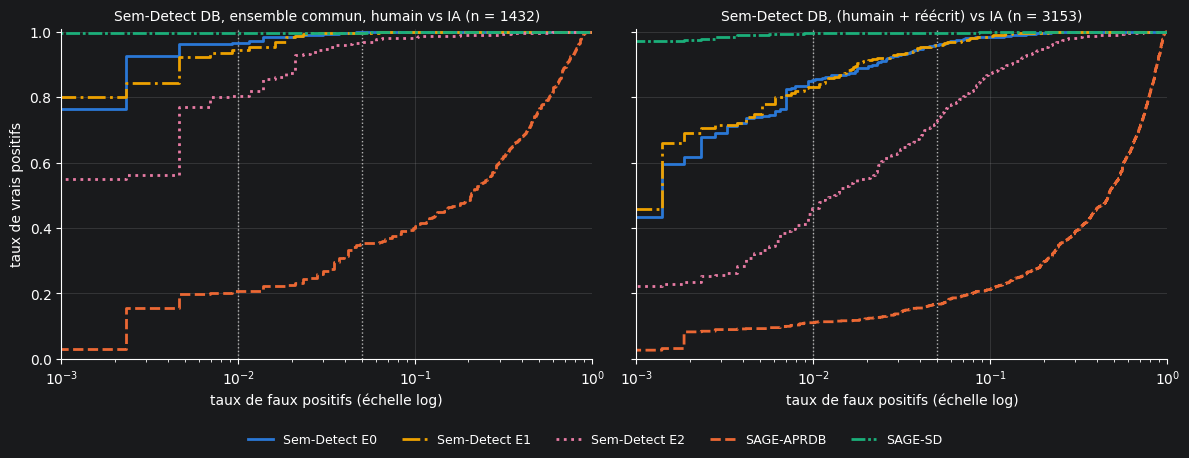

AUC par générateur de la cible (IA du générateur vs toutes les humaines, ensemble commun) :


,n IA,n nég.,Sem-Detect E0,Sem-Detect E1,Sem-Detect E2,SAGE-APRDB,SAGE-SD
deepseek.v3-v1:0,250,432,0.9982,0.9982,0.9935,0.8706,1.0000
gemini-2.5-flash,250,432,0.9991,0.9988,0.9955,0.7431,1.0000
gemini-2.5-pro,250,432,0.9990,0.9974,0.9852,0.4672,0.9995
qwen.qwen3-235b-a22b-2507-v1:0,250,432,0.9983,0.9981,0.9833,0.8022,1.0000


AUC par conférence et année (ensemble commun) :


n IA  n nég.  Sem-Detect E0  Sem-Detect E1  Sem-Detect E2  \
ICLR    2021   296     117         0.9981         0.9967         0.9880   
        2022   200     105         0.9979         0.9986         0.9829   
NeurIPS 2021   168      68         0.9994         0.9981         0.9891   
        2022   336     142         0.9991         0.9988         0.9934   

              SAGE-APRDB  SAGE-SD  
ICLR    2021      0.7853   0.9997  
        2022      0.6814   0.9998  
NeurIPS 2021      0.7019   1.0000  
        2022      0.7042   1.0000

In [26]:
# notebook : semdetect_sage_recap.ipynb — cellule 10 : figures, partie A
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
plot_roc(axes[0], es_A, ALL_A, f"Sem-Detect DB, ensemble commun, humain vs IA (n = {len(es_A['y'])})")
plot_roc(axes[1], es_A_hr, ALL_A, f"Sem-Detect DB, (humain + réécrit) vs IA (n = {len(es_A_hr['y'])})")
axes[0].set_ylabel("taux de vrais positifs")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(RECAP_DIR / "roc_partie_A.png", dpi=150)
plt.show()

gen_A = auc_by_group(es_A["ids"], te_idx, ALL_A, by="generator")
eds_A = auc_by_group(es_A["ids"], te_idx, ALL_A, by=["conference", "year"])
TABLES["A_auc_par_generateur"], TABLES["A_auc_par_edition"] = gen_A, eds_A
print("AUC par générateur de la cible (IA du générateur vs toutes les humaines, ensemble commun) :")
display(gen_A.round(4))
print("AUC par conférence et année (ensemble commun) :")
display(eds_A.round(4))

### Lecture de la partie A

À vérifier dans l'ordre :

1. **La cellule 6 reproduit-elle l'historique ?** C'est le cas si les cibles classées et la macro-F1 de E0, E1 et E2 sont conformes. Sinon, les comparaisons suivantes ne sont pas interprétables.
2. **Le contrôle SAGE de la cellule 7** doit redonner 0,7168 pour SAGE-APRDB et 0,9999 pour SAGE-SD sur les 1 970 cibles. Cela prouve que le chargeur du notebook équivaut à `run_eval`.
3. **L'écart principal se lit dans « Sem-Detect E0 − SAGE-APRDB ».** Il mesure ce qu'apporte l'accès à des références du même papier, issues de la même campagne de génération, face à un détecteur sans référence et hors distribution. **« Sem-Detect E2 − SAGE-APRDB »** en est la version plus réaliste, même si E2 est pénalisé par la troncature du nettoyage.
4. **(Humain + réécrit) contre IA.** Une réécriture par LLM d'un texte humain hérite des actes de langage de l'humain, mais pas de son style. La table « score SAGE par classe » dit si SAGE place les réécritures du côté humain ou du côté IA.
5. **L'effet de sélection.** Si l'AUC de SAGE monte quand on passe de « toutes » à « commun », c'est que les cibles exclues par Sem-Detect (des humaines courtes) étaient difficiles pour SAGE, et inversement.
6. **SAGE-SD** n'est pas un concurrent légitime tant que le raccourci n'est pas écarté. Il sert ici de borne et de témoin.

# 3. Partie B : APRDB, pilote E3 (1 000 `review-id`)

**Plan.** On recalcule Sem-Detect E3 en variantes (a) et (b) depuis les caches, avec le protocole du papier sur les jumelles du même `review-id` (R2). On score ensuite les cibles du pilote avec les deux SAGE, sur le **texte brut** d'APRDB. C'est l'entrée en distribution de SAGE-APRDB : `strip_markdown` ne concerne que Sem-Detect.

**Régimes.**

| Détecteur | Régime sur APRDB |
|---|---|
| SAGE-APRDB | en distribution : même dataset (test contre calibration), mêmes générateurs |
| Sem-Detect E3 | transfert du classifieur, mais **références natives** issues de la même campagne de génération (condition favorable) |
| SAGE-SD | transfert inverse : **résultat nouveau**. S'il s'effondre, l'argument du raccourci appris sur Sem-Detect DB se renforce |

In [27]:
# notebook : semdetect_sage_recap.ipynb — cellule 11 : univers du pilote et Sem-Detect E3 (a), (b)
universe = pd.read_parquet(E3_DIR / "pilot_universe.parquet")
print(f"univers : {len(universe)} reviews | {universe['group'].nunique()} review-id | "
      f"cibles {universe['is_target'].sum()} {universe.loc[universe['is_target'], 'class'].value_counts().to_dict()}")


def variant_frame(variant: str) -> pd.DataFrame:
    """Identique à la cellule 5 de semdetect_e3 : identifiants préfixés, textes nettoyés."""
    v = universe.copy()
    v["review-id"] = f"aprdb:{variant}:" + v["uid"]
    v["content"] = v["content"].map(CLEANERS[variant])
    return v


frames_B, stores_B = {}, {}
for v in ("a", "b"):
    df_v = variant_frame(v)
    store = SemDetectFeatureStore(root=STORE_ROOT, claims_source=CLAIMS_TAG,
                                  text_source=f"aprdb:test:clean_{v}", device=FEATURES_DEVICE)
    miss_emb = sum(not has_embedding(store, r) for r in df_v["review-id"])
    miss_txt = sum(not has_textual(store, r) for r in df_v.loc[df_v["is_target"], "review-id"])
    print(f"({v}) absents du cache : embeddings {miss_emb}, stats textuelles des cibles {miss_txt} (attendu : 0 / 0)")
    if miss_emb or miss_txt:
        raise RuntimeError("cache E3 incomplet : relancer la cellule 6 de semdetect_e3")
    frames_B[v], stores_B[v] = df_v, store


def evaluate_variant(v: str) -> tuple:
    df_v, store = frames_B[v], stores_B[v]
    refs = paper_protocol_references(df_v, k=3, seed=0, key_cols=["group"],
                                     is_valid=lambda rid: store.semantic(rid, 1) is not None)
    P, X, skipped = run_semdetect(store, refs, df_v.loc[df_v["is_target"], "review-id"])
    prefix = f"aprdb:{v}:"
    P.index = [r[len(prefix):] for r in P.index]   # retour à l'uid, commun aux variantes et à SAGE
    X.index = P.index
    return P, X, {r[len(prefix):]: why for r, why in skipped.items()}


res_B = {v: evaluate_variant(v) for v in ("a", "b")}
meta_B = universe[universe["is_target"]].drop_duplicates("uid").set_index("uid")[
    ["group", "class", "generator", "conference", "year", "content"]]

EXPECTED_B = {"a": (1850, 0.9799, 0.6994), "b": (1850, 0.9821, 0.6482)}
for v, (P, _, skipped) in res_B.items():
    y = meta_B.loc[P.index, "class"].eq("ai").to_numpy()
    met = all_metrics(y, P["p_ai"].to_numpy())
    n0, auc0, tpr0 = EXPECTED_B[v]
    ok = len(P) == n0 and abs(met["AUC"] - auc0) < 5e-4 and abs(met["TPR@1%"] - tpr0) < 5e-4
    by = pd.Series(skipped, dtype=object).to_frame("raison").join(meta_B["class"]).value_counts().to_dict()
    print(f"{'✅' if ok else '⚠️'} ({v}) {len(P)} classées (attendu {n0}) | AUC {met['AUC']:.4f} (attendu {auc0}) | "
          f"TPR@1% {met['TPR@1%']:.4f} (attendu {tpr0}) | non classables {len(skipped)} {by}")

univers : 4996 reviews | 1000 review-id | cibles 1918 {'human': 1000, 'ai': 918}


INFO:src.detector.sem_detect.feature_store:Feature store : 15422 embeddings (fbbbe1608d0e), 1918 stats textuelles (cdedf1ab8567)


(a) absents du cache : embeddings 0, stats textuelles des cibles 0 (attendu : 0 / 0)


INFO:src.detector.sem_detect.feature_store:Feature store : 15422 embeddings (fbbbe1608d0e), 1918 stats textuelles (cf890d2baa4a)


(b) absents du cache : embeddings 0, stats textuelles des cibles 0 (attendu : 0 / 0)
✅ (a) 1850 classées (attendu 1850) | AUC 0.9799 (attendu 0.9799) | TPR@1% 0.6994 (attendu 0.6994) | non classables 68 {('cible < 4 claims sémantiques', 'human'): 55, ('cible < 4 claims sémantiques', 'ai'): 8, ('références insuffisantes (2/3)', 'ai'): 5}
✅ (b) 1850 classées (attendu 1850) | AUC 0.9821 (attendu 0.9821) | TPR@1% 0.6482 (attendu 0.6482) | non classables 68 {('cible < 4 claims sémantiques', 'human'): 54, ('cible < 4 claims sémantiques', 'ai'): 9, ('références insuffisantes (2/3)', 'ai'): 5}


In [28]:
# notebook : semdetect_sage_recap.ipynb — cellule 12 : scores SAGE sur les cibles du pilote (texte brut, GPU 1 libre)
sage_B = {}
for name in SAGE_PRESETS:
    s = sage_scores(name, "aprdb:" + meta_B.index.to_series(), meta_B["content"])
    sage_B[name] = s.set_axis(meta_B.index.to_numpy()).rename(name)

SD_B = {f"Sem-Detect E3 ({v})": res_B[v][0]["p_ai"].rename(f"Sem-Detect E3 ({v})") for v in res_B}
ALL_B = {**SD_B, **sage_B}

# toutes les cibles du pilote (SAGE seul) : SAGE ne refuse aucune cible
es_B_all = make_evalset(meta_B.index, meta_B["class"].eq("ai"), meta_B["group"])
TABLES["B_SAGE_toutes_cibles"] = score_table(es_B_all, sage_B)
show(TABLES["B_SAGE_toutes_cibles"], "=== SAGE, toutes les cibles du pilote (humain vs IA) ===")

SAGE-APRDB : 1918 en cache, 0 à scorer
SAGE-SD : 1918 en cache, 0 à scorer
=== SAGE, toutes les cibles du pilote (humain vs IA) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
SAGE-APRDB,1918,918,1000,1000,"0.9530 [0.944, 0.962]","0.5087 [0.382, 0.635]","0.7418 [0.696, 0.787]"
SAGE-SD,1918,918,1000,1000,"0.7709 [0.748, 0.793]","0.0501 [0.036, 0.065]","0.1166 [0.072, 0.153]"


In [29]:
# notebook : semdetect_sage_recap.ipynb — cellule 13 : comparaison appariée sur les cibles communes
common_B = res_B["a"][0].index.intersection(res_B["b"][0].index)
sub_B = meta_B.loc[meta_B.index.isin(common_B)]
es_B = make_evalset(sub_B.index, sub_B["class"].eq("ai"), sub_B["group"])
TABLES["B_commun"] = score_table(es_B, ALL_B)
show(TABLES["B_commun"], f"=== Pilote APRDB, cibles classées en (a) et (b) : {len(es_B['y'])} (humain vs IA) ===")

TABLES["B_deltas"] = delta_table(es_B, {
    "Sem-Detect E3 (a) − SAGE-APRDB": (sage_B["SAGE-APRDB"], SD_B["Sem-Detect E3 (a)"]),
    "Sem-Detect E3 (b) − SAGE-APRDB": (sage_B["SAGE-APRDB"], SD_B["Sem-Detect E3 (b)"]),
    "SAGE-SD − SAGE-APRDB": (sage_B["SAGE-APRDB"], sage_B["SAGE-SD"]),
    "Sem-Detect E3 (b) − (a)": (SD_B["Sem-Detect E3 (a)"], SD_B["Sem-Detect E3 (b)"]),
})
print("\n=== Écarts appariés, IC95 bootstrap en grappes (review-id) ===")
display(TABLES["B_deltas"].round(4))

# cibles exclues par Sem-Detect : étaient-elles faciles ou difficiles pour SAGE ?
excluded_B = meta_B.index.difference(common_B)
ex = meta_B.loc[excluded_B]
print(f"\n{len(excluded_B)} cibles exclues par Sem-Detect : {ex['class'].value_counts().to_dict()}")
rows = []
for name, s in sage_B.items():
    for label, idx in (("exclues", excluded_B), ("communes", common_B)):
        g = s.loc[idx].groupby(meta_B.loc[idx, "class"])
        for cls, v in g:
            rows.append({"ensemble": label, "classe": cls, "modèle": name, "n": len(v), "score moyen": v.mean(),
                         "part > 0,5": (v > 0.5).mean()})
TABLES["B_exclues_score_SAGE"] = (pd.DataFrame(rows)
                                  .pivot_table(index=["ensemble", "classe", "n"], columns="modèle",
                                               values=["score moyen", "part > 0,5"])
                                  .round(3))
print("score SAGE selon l'ensemble et la classe :")
display(TABLES["B_exclues_score_SAGE"])

=== Pilote APRDB, cibles classées en (a) et (b) : 1841 (humain vs IA) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect E3 (a),1841,903,938,990,"0.9801 [0.974, 0.986]","0.6999 [0.539, 0.787]","0.9059 [0.860, 0.952]"
Sem-Detect E3 (b),1841,903,938,990,"0.9822 [0.977, 0.987]","0.6489 [0.564, 0.790]","0.9280 [0.898, 0.954]"
SAGE-APRDB,1841,903,938,990,"0.9590 [0.951, 0.967]","0.5161 [0.392, 0.649]","0.7530 [0.705, 0.813]"
SAGE-SD,1841,903,938,990,"0.7971 [0.776, 0.818]","0.0509 [0.037, 0.073]","0.1661 [0.126, 0.231]"



=== Écarts appariés, IC95 bootstrap en grappes (review-id) ===


Δ (b − a)  IC95 bas  IC95 haut  \
comparaison                    métrique                                   
Sem-Detect E3 (a) − SAGE-APRDB AUC          0.0211    0.0113     0.0312   
                               TPR@1%       0.1838   -0.0055     0.3485   
                               TPR@5%       0.1528    0.0781     0.2248   
Sem-Detect E3 (b) − SAGE-APRDB AUC          0.0232    0.0139     0.0325   
                               TPR@1%       0.1329   -0.0258     0.3313   
                               TPR@5%       0.1750    0.1127     0.2293   
SAGE-SD − SAGE-APRDB           AUC         -0.1619   -0.1831    -0.1419   
                               TPR@1%      -0.4651   -0.6009    -0.3376   
                               TPR@5%      -0.5869   -0.6562    -0.5088   
Sem-Detect E3 (b) − (a)        AUC          0.0021   -0.0018     0.0059   
                               TPR@1%      -0.0509   -0.1477     0.0829   
                               TPR@5%       0.0221   -0.0119     0.0616   

                                         part bootstrap Δ ≤ 0  
comparaison                    métrique                        
Sem-Detect E3 (a) − SAGE-APRDB AUC                      0.000  
                               TPR@1%                   0.033  
                               TPR@5%                   0.000  
Sem-Detect E3 (b) − SAGE-APRDB AUC                      0.000  
                               TPR@1%                   0.062  
                               TPR@5%                   0.000  
SAGE-SD − SAGE-APRDB           AUC                      1.000  
                               TPR@1%                   1.000  
                               TPR@5%                   1.000  
Sem-Detect E3 (b) − (a)        AUC                      0.152  
                               TPR@1%                   0.654  
                               TPR@5%                   0.184


77 cibles exclues par Sem-Detect : {'human': 62, 'ai': 15}
score SAGE selon l'ensemble et la classe :


part > 0,5         score moyen        
modèle              SAGE-APRDB SAGE-SD  SAGE-APRDB SAGE-SD
ensemble classe n                                         
communes ai     903      0.888   0.040       0.821   0.050
         human  938      0.113   0.004       0.120   0.009
exclues  ai     15       0.733   0.000       0.619   0.011
         human  62       0.419   0.000       0.404   0.067

AUC par générateur de la cible (IA du générateur vs toutes les humaines, cibles communes) :


,n IA,n nég.,Sem-Detect E3 (a),Sem-Detect E3 (b),SAGE-APRDB,SAGE-SD
gemini,201,938,0.9826,0.9852,0.9600,0.7766
gpt4o,230,938,0.9691,0.9703,0.9707,0.7981
llama,212,938,0.9710,0.9754,0.9363,0.7544
qwen,260,938,0.9953,0.9960,0.9665,0.8470


AUC par conférence et année (cibles communes) :


n IA  n nég.  Sem-Detect E3 (a)  Sem-Detect E3 (b)  SAGE-APRDB  \
ICLR    2017    54      53             0.9867             0.9846      0.9713   
        2018    82      79             0.9954             0.9971      0.9455   
        2019    71      74             0.9861             0.9880      0.9406   
        2020    85      94             0.9902             0.9936      0.9448   
        2021    91     102             0.9931             0.9930      0.9930   
NeurIPS 2016   168     163             0.9942             0.9898      0.9271   
        2017    75      78             0.9868             0.9882      0.9685   
        2018    99     101             0.9917             0.9863      0.9554   
        2019    82      94             0.9839             0.9868      0.9511   
        2021    96     100             0.9299             0.9470      0.9921   

              SAGE-SD  
ICLR    2017   0.8477  
        2018   0.7260  
        2019   0.7303  
        2020   0.4787  
        2021   0.7933  
NeurIPS 2016   0.8219  
        2017   0.9427  
        2018   0.8782  
        2019   0.8635  
        2021   0.8525

OSError: [Errno 28] No space left on device

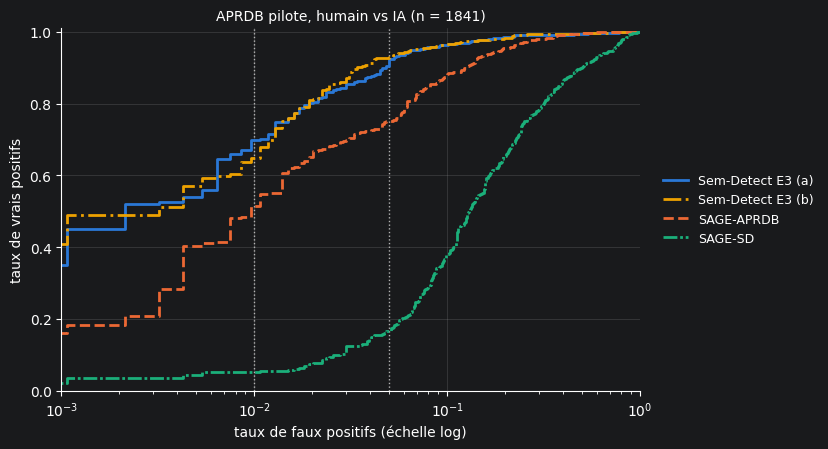

In [30]:
# notebook : semdetect_sage_recap.ipynb — cellule 14 : stratification et figures, partie B
gen_B = auc_by_group(es_B["ids"], meta_B, ALL_B, by="generator")
eds_B = auc_by_group(es_B["ids"], meta_B, ALL_B, by=["conference", "year"])
TABLES["B_auc_par_generateur"], TABLES["B_auc_par_edition"] = gen_B, eds_B
print("AUC par générateur de la cible (IA du générateur vs toutes les humaines, cibles communes) :")
display(gen_B.round(4))
print("AUC par conférence et année (cibles communes) :")
display(eds_B.round(4))

fig, ax = plt.subplots(figsize=(8.4, 4.6))
plot_roc(ax, es_B, ALL_B, f"APRDB pilote, humain vs IA (n = {len(es_B['y'])})")
ax.set_ylabel("taux de vrais positifs")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(RECAP_DIR / "roc_partie_B.png", dpi=150)
plt.show()

# AUC par générateur : un panneau par dataset, mêmes couleurs par détecteur
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, (title, tab, dets) in zip(axes, [("Sem-Detect DB (ensemble commun)", gen_A, list(ALL_A)),
                                          ("APRDB pilote (cibles communes)", gen_B, list(ALL_B))]):
    ypos = np.arange(len(tab))
    for j, det in enumerate(dets):
        color, _ = STYLE.get(det, ("#6b6b6b", "-"))
        ax.scatter(tab[det], ypos + (j - (len(dets) - 1) / 2) * 0.13, s=46, color=color,
                   edgecolor="white", linewidth=1.2, label=det, zorder=3)
    ax.set_yticks(ypos, tab.index)
    ax.grid(axis="x", alpha=0.25, lw=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("AUC (IA du générateur vs humaines)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(RECAP_DIR / "auc_par_generateur.png", dpi=150)
plt.show()

### Lecture de la partie B

1. **Le contrôle de la cellule 11** doit redonner exactement le pilote : 1 850 cibles, AUC de 0,9799 en (a) et de 0,9821 en (b).
2. **SAGE-APRDB sur le pilote** doit rester proche de son AUC sur le test complet (0,9548), sans quoi le tirage du pilote serait atypique. Les deux tables de la cellule 12 (toutes les cibles) et de la cellule 13 (cibles communes) montrent en plus l'effet des exclusions de Sem-Detect.
3. **La comparaison principale se lit dans « Sem-Detect E3 (a) − SAGE-APRDB ».** Elle oppose un détecteur en distribution, sans référence, à un détecteur en transfert qui dispose de références natives. Le signe de Δ AUC et celui de Δ TPR@1 % peuvent différer : regarder les deux.
4. **Llama et NeurIPS 2021 sont les deux points faibles** connus de Sem-Detect sur le pilote. La stratification dit si SAGE partage ces faiblesses, ce qui pointerait vers une propriété des données, ou s'il les compense, ce qui en ferait des détecteurs complémentaires.
5. **SAGE-SD sur APRDB** est le test du raccourci. Une AUC élevée voudrait dire que SAGE-SD a appris un signal d'auteur qui transfère. Une AUC proche de 0,5, ou inversée, voudrait dire qu'il a appris un artefact propre à Sem-Detect DB.

# 4. Partie C : synthèse croisée

La grille croise **détecteur × dataset**. La marque « ★ » signale le régime en distribution. Les cellules ne sont pas toutes calculées sur le même ensemble : chaque colonne utilise l'ensemble commun de sa partie, et le tableau le rappelle.

In [ ]:
# notebook : semdetect_sage_recap.ipynb — cellule 15 : grille détecteur × dataset
def cell(tab: pd.DataFrame, row: str, star: bool) -> str:
    r = tab.loc[row]
    return (f"{'★ ' if star else ''}AUC {r['AUC']:.3f} [{r['AUC_lo']:.3f}, {r['AUC_hi']:.3f}] · "
            f"TPR@1% {r['TPR@1%']:.3f} [{r['TPR@1%_lo']:.3f}, {r['TPR@1%_hi']:.3f}]")


col_A = f"Sem-Detect DB : test, humain vs IA, commun E0∩E1∩E2 (n = {len(es_A['y'])})"
col_B = f"APRDB : pilote, humain vs IA, commun (a)∩(b) (n = {len(es_B['y'])})"
ROWS = ["SAGE-APRDB", "SAGE-SD",
        "Sem-Detect, claims Gemini + réf. du dataset (E0)",
        "Sem-Detect, claims Qwen3-32B + réf. du dataset / natives (E1 ; E3 a)",
        "Sem-Detect, claims Qwen3-32B + réf. locales (E2)"]
grid = pd.DataFrame({
    col_A: [
        cell(TABLES["A_commun"], "SAGE-APRDB", False),
        cell(TABLES["A_commun"], "SAGE-SD", True) + " (suspect)",
        cell(TABLES["A_commun"], "Sem-Detect E0", True),
        cell(TABLES["A_commun"], "Sem-Detect E1", True),
        cell(TABLES["A_commun"], "Sem-Detect E2", True) + " (borne basse)",
    ],
    col_B: [
        cell(TABLES["B_commun"], "SAGE-APRDB", True),
        cell(TABLES["B_commun"], "SAGE-SD", False),
        "non applicable (pas de claims Gemini pour APRDB)",
        cell(TABLES["B_commun"], "Sem-Detect E3 (a)", False) + " (réf. natives R2)",
        "non mesuré (pas de références générées localement pour APRDB)",
    ],
}, index=ROWS)
TABLES["C_grille"] = grid
with pd.option_context("display.max_colwidth", None):
    display(grid)
print("Historique hors grille : SAGE-APRDB sur le test APRDB complet (9 468 cibles) = AUC 0,9548, TPR@1 % 0,456.")

In [ ]:
# notebook : semdetect_sage_recap.ipynb — cellule 16 : export (tableaux CSV, scores parquet, figures déjà écrites)
out_dir = RECAP_DIR / "tables"
out_dir.mkdir(exist_ok=True)
for key, tab in TABLES.items():
    tab.to_csv(out_dir / f"{key}.csv")

scores_A = te[["review-id", "class", "generator", "rating", "conference", "year", "submission_id"]].set_index("review-id")
for name, s in ALL_A.items():
    scores_A[name] = s                       # NaN = cible non classée par cette configuration
scores_A["commun"] = scores_A.index.isin(common_A)
scores_A.to_parquet(RECAP_DIR / "scores_partie_A.parquet")

scores_B = meta_B.drop(columns=["content"]).copy()
for name, s in ALL_B.items():
    scores_B[name] = s
scores_B["commun"] = scores_B.index.isin(common_B)
scores_B.to_parquet(RECAP_DIR / "scores_partie_B.parquet")

print(f"{len(TABLES)} tableaux -> {out_dir}")
print(f"scores -> {RECAP_DIR / 'scores_partie_A.parquet'} ({len(scores_A)}) et {RECAP_DIR / 'scores_partie_B.parquet'} ({len(scores_B)})")
print(f"figures -> {sorted(p.name for p in RECAP_DIR.glob('*.png'))}")

# 5. Conclusions établies et points ouverts

## Établi avant ce notebook

1. **Sem-Detect est reproduit** (E0) : macro-F1 de 0,8418 contre 0,84 dans le papier, avec le protocole du papier. Le script officiel fuit (auto-référence, références du même modèle) et gonfle la macro-F1 d'environ 0,01.
2. **L'extracteur local coûte peu** (E1) : −0,016 de macro-F1 (IC95 entre −0,026 et −0,006). Le classement binaire est quasi intact (AUC 0,996).
3. **Les références conditionnent tout** (E2). Avec des références qui ne sortent pas de la campagne de génération des cibles, l'écart de similarité IA − humain se réduit de 0,104 à 0,077, et le rappel IA chute de 0,84 à 0,55. Ce chiffre est une borne haute de la dégradation (troncature du nettoyage non corrigée). Le mécanisme est néanmoins établi : **la force de Sem-Detect dépend de la proximité entre références et cibles**.
4. **Sur APRDB en R2** (E3 pilote), cette condition est remplie par construction (jumelles natives). Le classement transfère (AUC 0,98), mais les décisions à 3 classes sont très conservatrices : 57 % des IA sont rangées en « réécrit ». Llama et NeurIPS 2021 sont les points faibles.
5. **SAGE-APRDB transfère mal vers Sem-Detect DB** (AUC 0,717), avec un mode d'échec asymétrique : les IA de Sem-Detect lui paraissent humaines. **La contamination n'est pas un facteur** (0,720 après décontamination).
6. **SAGE-SD à 0,9999 n'est pas interprétable** tant que le raccourci (gabarit, longueur, prétraitement asymétrique) n'est pas écarté.

## Établi par ce notebook

À lire dans les cellules 8, 9, 13 et 15 :

- l'écart apparié Sem-Detect − SAGE sur chaque dataset, en AUC et en TPR@1 % ;
- le transfert inverse SAGE-SD → APRDB ;
- l'effet de sélection des exclusions de Sem-Detect sur SAGE ;
- le partage, ou non, des faiblesses par générateur et par édition.

## Points ouverts, par priorité suggérée

1. **E3 complet sur les 9 468 cibles** (≈ 14 h d'extraction), pour une comparaison sur l'ensemble d'évaluation officiel de SAGE plutôt que sur un pilote.
2. **Correction du nettoyage d'E2** (concaténer tous les blocs `{{{…}}}`, nouveaux identifiants `ref:v2:`), pour transformer la borne de E2 en estimation.
3. **Diagnostics du raccourci de SAGE-SD** (A : baselines triviales de longueur et de format ; B : prétraitement symétrisé ; C : stratification), à éclairer par le transfert inverse mesuré ici.
4. **SAGE-APRDB sur Sem-Detect 2022 seul** : le run est prévu, mais son résultat n'a pas été rapporté.
5. **Calibration d'un seuil binaire pour Sem-Detect** : la décision par argmax correspond à un FPR d'environ 0,2 % sur APRDB, et l'usage opérationnel demande un seuil explicite sur P(IA).
6. **Avant tout SAGE à 3 classes (T2)** : vérifier les doublons de contenu entre classes.

In [32]:
# notebook : semdetect_sage_recap.ipynb — cellule 17 : données de tab:cross_dataset (lecture seule, sans GPU)
from typing import Optional

import numpy as np
import pandas as pd

PAPER_ROWS = {  # ligne du papier -> nom du détecteur dans les parties A (Sem-Detect DB) et B (APRDB)
    "SAGE-APRDB": {"A": "SAGE-APRDB", "B": "SAGE-APRDB"},
    "SAGE-SD": {"A": "SAGE-SD", "B": "SAGE-SD"},
    "Sem-Detect": {"A": "Sem-Detect E0", "B": "Sem-Detect E3 (a)"},
}
PAPER_METRICS = {"AUC": "AUROC", "TPR@1%": "TPR@1%", "TPR@5%": "TPR@5%"}
COLUMNS = [("B", "APRDB"), ("A", "Sem-Detect")]   # ordre des blocs dans le papier


def load_table(key: str) -> pd.DataFrame:
    """Table en mémoire (cellules 8 et 13) ou, après redémarrage du noyau, export CSV de la cellule 16."""
    if "TABLES" in globals() and key in TABLES:
        return TABLES[key]
    path = RECAP_DIR / "tables" / f"{key}.csv"
    if not path.exists():
        raise FileNotFoundError(f"{key} introuvable en mémoire et dans {path} : exécuter les cellules 1 à 16")
    return pd.read_csv(path, index_col=0)


def fmt(row: pd.Series, metric: str) -> str:
    return f"{row[metric]:.4f} [{row[metric + '_lo']:.3f}, {row[metric + '_hi']:.3f}]"


def matches_p_ai(score: pd.Series, proba: pd.DataFrame) -> Optional[bool]:
    """Vrai si le score binaire est la colonne p_ai du LightGBM ; None si la comparaison est impossible."""
    ids = score.dropna().index.intersection(proba.index)
    if len(ids) == 0 or "p_ai" not in proba.columns:
        return None
    return bool(np.allclose(score.loc[ids].to_numpy(float), proba.loc[ids, "p_ai"].to_numpy(float)))


tab = {"A": load_table("A_commun"), "B": load_table("B_commun")}

# ------------------------------------------------------------------ 1. valeurs de la table
header = ["Detector"] + [f"{ds} {PAPER_METRICS[m]}" for _, ds in COLUMNS for m in PAPER_METRICS]
lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
for label, names in PAPER_ROWS.items():
    cells = [fmt(tab[part].loc[names[part]], m) for part, _ in COLUMNS for m in PAPER_METRICS]
    lines.append("| " + " | ".join([label] + cells) + " |")
print("=== 1. Valeurs de tab:cross_dataset (point [IC95]) ===")
print("\n".join(lines))

# ------------------------------------------------------------------ 2. effectifs
print("\n=== 2. Effectifs (doivent être identiques pour toutes les lignes d'une colonne) ===")
for part, ds in COLUMNS:
    t = tab[part].loc[[names[part] for names in PAPER_ROWS.values()], ["n", "n IA", "n nég.", "grappes"]]
    if (t.nunique() > 1).any():
        raise ValueError(f"{ds} : effectifs différents selon le détecteur, comparaison non appariée\n{t}")
    r = t.iloc[0].astype(int)
    unit = "papiers (submission_id)" if part == "A" else "reviews sources (review-id)"
    print(f"{ds:<10} n = {r['n']} | IA {r['n IA']} | humaines {r['n nég.']} | grappes {r['grappes']} {unit}")

# ------------------------------------------------------------------ 3. contrôle de dérive
print("\n=== 3. Contrôle contre les sorties déjà rapportées ===")
REPORTED = [  # (partie, détecteur b, détecteur a ou None, métrique, valeur rapportée)
    ("B", "SAGE-APRDB", None, "AUC", 0.9590),
    ("B", "SAGE-SD", None, "AUC", 0.7971),
    ("B", "Sem-Detect E3 (a)", None, "AUC", 0.9801),
    ("B", "Sem-Detect E3 (a)", None, "TPR@1%", 0.6999),
    ("A", "SAGE-SD", "SAGE-APRDB", "AUC", 0.2791),
    ("A", "SAGE-SD", "SAGE-APRDB", "TPR@1%", 0.7910),
    ("A", "SAGE-SD", "SAGE-APRDB", "TPR@5%", 0.6470),
    ("A", "Sem-Detect E0", "SAGE-APRDB", "AUC", 0.2779),
    ("A", "Sem-Detect E0", "SAGE-SD", "AUC", -0.0012),
    ("A", "Sem-Detect E0", "SAGE-SD", "TPR@1%", -0.0300),
]
for part, b, a, m, expected in REPORTED:
    t = tab[part]
    value = t.loc[b, m] - (t.loc[a, m] if a else 0.0)
    label = f"{b} − {a}" if a else b
    print(f"{'✅' if abs(value - expected) < 1.5e-4 else '⚠️'} {part} {label:<32} {m:<7} "
          f"{value:+.4f} (rapporté {expected:+.4f})")

# ------------------------------------------------------------------ 4a. pilote APRDB : du pilote à l'ensemble commun
print("\n=== 4a. Pilote APRDB : cibles du pilote -> ensemble commun ===")
if "meta_B" in globals() and "res_B" in globals():
    info_B = meta_B
    classified = {v: res_B[v][0].index for v in ("a", "b")}
    skipped = {v: dict(res_B[v][2]) for v in ("a", "b")}
else:   # noyau redémarré : NaN = cible non classée, d'après l'export de la cellule 16 (raisons indisponibles)
    info_B = pd.read_parquet(RECAP_DIR / "scores_partie_B.parquet")
    classified = {v: info_B.index[info_B[f"Sem-Detect E3 ({v})"].notna()] for v in ("a", "b")}
    skipped = {v: {} for v in ("a", "b")}

common_ids = classified["a"].intersection(classified["b"])
print(f"cibles du pilote {len(info_B)} | classées (a) {len(classified['a'])} | (b) {len(classified['b'])} "
      f"| communes {len(common_ids)}")
not_a = info_B.index.difference(classified["a"])
print(f"non classables en (a) : {len(not_a)} {info_B.loc[not_a, 'class'].value_counts().to_dict()} | raisons "
      f"{pd.Series([skipped['a'].get(u, 'inconnue') for u in not_a], dtype=object).value_counts().to_dict()}")
for v, other in (("a", "b"), ("b", "a")):
    only = classified[v].difference(classified[other])
    reasons = pd.Series([skipped[other].get(u, "inconnue") for u in only], dtype=object)
    print(f"classées en ({v}) mais pas en ({other}) : {len(only)} "
          f"{info_B.loc[only, 'class'].value_counts().to_dict()} | raison en ({other}) : "
          f"{reasons.value_counts().to_dict()}")

# ------------------------------------------------------------------ 4b. Sem-Detect DB : effet de la restriction
print("\n=== 4b. Sem-Detect DB : effectifs et AUC de SAGE selon l'ensemble retenu ===")
display(load_table("A_selection_SAGE").round(4))

# ------------------------------------------------------------------ 4c. score binaire de Sem-Detect
print("\n=== 4c. Score binaire de Sem-Detect ===")
checks = []
if "res_B" in globals() and "ALL_B" in globals():
    checks.append(("B", "Sem-Detect E3 (a)", ALL_B["Sem-Detect E3 (a)"], res_B["a"][0]))
if "res_A" in globals() and "ALL_A" in globals():
    src = res_A.get("E0") if isinstance(res_A, dict) else None
    if isinstance(src, tuple) and isinstance(src[0], pd.DataFrame):
        checks.append(("A", "Sem-Detect E0", ALL_A["Sem-Detect E0"], src[0]))
    else:
        print("A : structure de res_A non reconnue, vérifier la définition de SD_A dans la cellule 6")
for part, name, s, proba in checks:
    print(f"{part} {name} : sorties du classifieur {list(proba.columns)} | score = p_ai : {matches_p_ai(s, proba)}")
if not checks:
    print("res_A / res_B absents : relancer les cellules 6 et 11")

# ------------------------------------------------------------------ 4d. bootstrap
print("\n=== 4d. Bootstrap ===")
if "make_evalset" in globals():
    print(f"défauts de make_evalset (n_boot, seed) : {make_evalset.__defaults__} | IC percentile 2,5–97,5 %")
for part, es_name in (("A", "es_A"), ("B", "es_B")):
    if es_name in globals():
        es = globals()[es_name]
        print(f"{part} : {len(es['boot'])} réplicats en grappes sur {es['n_clusters']} grappes")
    else:
        print(f"{part} : {es_name} absent | N_BOOT = {globals().get('N_BOOT', 'inconnu')}")

# ------------------------------------------------------------------ 4e. contamination (note éventuelle)
print("\n=== 4e. Humaines du test Sem-Detect vues à l'entraînement par SAGE-APRDB ===")
try:
    dec = load_table("A_commun_decontamine")
    for name in ("SAGE-APRDB", "SAGE-SD"):
        print(f"{name} : AUC commun {tab['A'].loc[name, 'AUC']:.4f} -> sans contaminées "
              f"{dec.loc[name, 'AUC']:.4f} (n = {int(dec.loc[name, 'n'])})")
except FileNotFoundError:
    print("A_commun_decontamine absent : aucune contamination détectée en cellule 8")

=== 1. Valeurs de tab:cross_dataset (point [IC95]) ===
| Detector | APRDB AUROC | APRDB TPR@1% | APRDB TPR@5% | Sem-Detect AUROC | Sem-Detect TPR@1% | Sem-Detect TPR@5% |
|---|---|---|---|---|---|---|
| SAGE-APRDB | 0.9590 [0.951, 0.967] | 0.5161 [0.392, 0.649] | 0.7530 [0.705, 0.813] | 0.7208 [0.692, 0.749] | 0.2060 [0.157, 0.253] | 0.3510 [0.260, 0.393] |
| SAGE-SD | 0.7971 [0.776, 0.818] | 0.0509 [0.037, 0.073] | 0.1661 [0.126, 0.231] | 0.9999 [1.000, 1.000] | 0.9970 [0.994, 1.000] | 0.9980 [0.995, 1.000] |
| Sem-Detect | 0.9801 [0.974, 0.986] | 0.6999 [0.539, 0.787] | 0.9059 [0.860, 0.952] | 0.9987 [0.997, 1.000] | 0.9670 [0.924, 0.993] | 0.9990 [0.991, 1.000] |

=== 2. Effectifs (doivent être identiques pour toutes les lignes d'une colonne) ===
APRDB      n = 1841 | IA 903 | humaines 938 | grappes 990 reviews sources (review-id)
Sem-Detect n = 1432 | IA 1000 | humaines 432 | grappes 138 papiers (submission_id)

=== 3. Contrôle contre les sorties déjà rapportées ===
✅ B SAGE-APRDB 

,n humaines,n IA,SAGE-APRDB AUC,SAGE-SD AUC
toutes (1970),606,1364,0.7168,0.9999
classées E0,599,1364,0.7193,0.9999
classées E1,598,1360,0.7191,0.9999
classées E2,433,1003,0.7207,0.9999
commun,432,1000,0.7208,0.9999



=== 4c. Score binaire de Sem-Detect ===
B Sem-Detect E3 (a) : sorties du classifieur ['p_ai', 'p_rewrite', 'p_human'] | score = p_ai : True
A Sem-Detect E0 : sorties du classifieur ['p_ai', 'p_rewrite', 'p_human'] | score = p_ai : True

=== 4d. Bootstrap ===
défauts de make_evalset (n_boot, seed) : (1000, 0) | IC percentile 2,5–97,5 %
A : 1000 réplicats en grappes sur 138 grappes
B : 1000 réplicats en grappes sur 990 grappes

=== 4e. Humaines du test Sem-Detect vues à l'entraînement par SAGE-APRDB ===
SAGE-APRDB : AUC commun 0.7208 -> sans contaminées 0.7207 (n = 1402)
SAGE-SD : AUC commun 0.9999 -> sans contaminées 0.9999 (n = 1402)


In [33]:
# notebook : semdetect_sage_recap.ipynb — cellule 18 : Acc max sur le pilote APRDB (ensemble commun)
import numpy as np
from sklearn.metrics import roc_curve

for name in ("Sem-Detect E3 (a)", "SAGE-APRDB"):
    v, y = aligned(es_B, ALL_B[name]), es_B["y"]
    fpr, tpr, _ = roc_curve(y, v, drop_intermediate=False)
    pos, neg = int(y.sum()), int(len(y) - y.sum())
    acc_max = ((tpr * pos + (1 - fpr) * neg) / (pos + neg)).max()
    print(f"{name} : n {len(y)} | AUC {all_metrics(y, v)['AUC']:.4f} | acc max {acc_max:.4f}")

Sem-Detect E3 (a) : n 1841 | AUC 0.9801 | acc max 0.9424
SAGE-APRDB : n 1841 | AUC 0.9590 | acc max 0.8919
